# Comparative Evaluation of LLM Models — Electronic Health Record (EHR) Auditor

This notebook compares candidate LLM models (Qwen2.5-3B, Phi-4-mini-instruct e Llama 3.2 3B) using the endpoint already integrated with the system.

**Prerequisites:**
- The system endpoint running locally (LM Studio + your backend)
- Structured ground truth in `data/gabarito.csv`
- Test records in `data/prontuarios.json`


In [69]:
%pip install requests python-dotenv pandas numpy scikit-learn matplotlib seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Setup and imports

In [70]:
import copy
import hashlib
import json
import os
import re
import time
import requests
import pandas as pd
import numpy as np
from pathlib import Path
from dotenv import load_dotenv
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Paths
DATA_DIR = Path('data')
RESULTS_DIR = DATA_DIR / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Full list of candidate models (general reference for the study)
ALL_MODELS = [
    "qwen2.5-3b-instruct",
    "phi-4-mini-instruct",
    "llama-3.2-3b-instruct",
]

N_REPETITIONS = 1
# Seed sent to the LLM (via Producer -> Worker). Set to None to NOT send one: the model then samples randomly.
SEED = 42

# Auditable fields per section.
# NOTE: these section/field keys ("secao_a", "hda", "escala_braden", ...) are
# NOT translated — they must match the exact keys returned by the backend's
# audit_data JSON payload, so changing them would break the lookup below.
AUDITABLE_FIELDS = {
    "secao_a": [
        "diagnostico_internacao",
    ],
    "secao_b_anamnese": [
        "hda", "hd_cid", "ap_app", "af", "exame_fisico", "cd", "criacao_anamnese",
    ],
    "secao_b_evolucao": [
        "hd_cid", "exame_fisico", "procedimentos_condutas_queixas", "frequencia_diaria",
    ],
    "secao_c": [
        "diagnostico_cid", "descricao_procedimento", "descricao_tecnica", "uso_opme",
    ],
    "secao_d_anamnese": [
        "motivo_internacao", "ap_app", "af", "exame_fisico",
        "escala_braden", "escala_morse", "cd", "criacao_anamnese",
    ],
    "secao_d_evolucao": [
        "motivo_internacao", "exame_fisico", "condutas",
        "escala_braden", "escala_morse", "curativo", "criacao_evolucao",
    ],
}

def clean_id(value):
    return re.sub(r'\D', '', str(value))

## 2. Load ground truth and test records

The ground truth needs to be in a structured format: one row per (record, field), with the expected label.

Expected format of the `gabarito.csv` file:

| record | section | field | professional category | record type | result | description missing | total conformity |
|---|---|---|---|---|---|---|---|
| 85826536 | secao_d_evolucao | escala_braden | ENFERMAGEM | Evolução | ausente | Escala de Braden não preenchida na evolução de enfermagem | Parcialmente Conforme | 
| 85826536 |  |  |  | | | | Conforme |

Where '' is `conforme` (the information is correctly recorded / compliant) or `ausente` (missing/not recorded).


In [71]:
ground_truth = pd.read_csv(DATA_DIR / 'gabarito.csv')
ground_truth['record'] = ground_truth['record'].apply(clean_id)

print(f"Total ground truth rows: {len(ground_truth)}")
print(f"Unique records: {ground_truth['record'].nunique()}")

conforme_records = ground_truth[ground_truth['total conformity'] == 'Conforme']['record'].nunique()
parcial_records = ground_truth[ground_truth['total conformity'] == 'Parcialmente Conforme']['record'].nunique()

print(f"Records Conforme: {conforme_records}")
print(f"Records Parcialmente Conforme: {parcial_records}")

ground_truth.head()

Total ground truth rows: 53
Unique records: 16
Records Conforme: 4
Records Parcialmente Conforme: 12


,record,section,field,professional category,record type,result,description missing,total conformity
0,94098934,secao_c,diagnostico_cid,MEDICINA,Cirúrgico,ausente,CID do diagnóstico cirúrgico não preenchido no...,Parcialmente Conforme
1,94098934,secao_d_anamnese,af,ENFERMAGEM,Anamnese,ausente,Antecedentes familiares não registrados na ana...,Parcialmente Conforme
2,99692381,NaN,NaN,NaN,NaN,NaN,NaN,Conforme
3,20981529,secao_b_anamnese,exame_fisico,MEDICINA,Anamnese,incompleta,Exame físico incompleto: faltam os sistemas AC...,Parcialmente Conforme
4,20981529,secao_c,diagnostico_cid,MEDICINA,Cirúrgico,ausente,CID do diagnóstico cirúrgico não preenchido,Parcialmente Conforme


In [72]:
N_PATIENTS = 1

with open(DATA_DIR / 'prontuarios.json', encoding='utf-8') as f:
    all_records = json.load(f)

# Only picks patients that exist in the ground truth
ground_truth_pids = set(ground_truth['record'].unique())

unique_records = []
for record_entry in all_records:
    pid = clean_id(record_entry.get('Prontuário', ''))
    if pid in ground_truth_pids and pid not in unique_records:
        unique_records.append(pid)
        if len(unique_records) == N_PATIENTS:
            break

test_records = [
    r for r in all_records
    if clean_id(r.get('Prontuário', '')) in unique_records
]

print(f"Sample reduced to: {len(unique_records)} unique records (all in ground truth).")
print(f"Total entries that will be sent to the endpoint: {len(test_records)}")

Sample reduced to: 1 unique records (all in ground truth).
Total entries that will be sent to the endpoint: 8


## 3. Parsing function for the AI "signature" tag

Every field sent to the AI comes back from the backend with a signature that says what happened:

| Value returned by the backend | `ai_outcome` | Meaning |
|---|---|---|
| `conforme (IA: <excerpt>)` / `não conforme (IA: <excerpt>)` / `conforme (validado por IA)` | `answered` | the AI ran and answered |
| `Não registrado (IA: null)` | `null` | the AI ran and answered `null` (looked, found nothing) — a valid answer |
| `Não registrado (IA_NAO_EXECUTADA: <reason>)` | `error` | the AI did NOT run (timeout, invalid JSON, ...) after 3 attempts |
| no tag | `not_sent` | resolved by the rule/regex engine, never sent to the AI |

In [73]:
AI_TAG = re.compile(r'\(IA:\s*(.*)\)\s*$', re.DOTALL)
AI_ERROR_TAG = re.compile(r'\(IA_NAO_EXECUTADA:\s*(.*?)\)\s*$', re.DOTALL)


def extract_ai_info(value):
    """
    Splits the value of a field returned by the endpoint into:
    - status: the general label ('conforme', 'Não registrado', 'não se aplica', etc.)
    - from_ai: True if the AI actually ran for this field (answered or null)
    - ai_excerpt: the text extracted by the AI, if any
    - ai_outcome: 'answered' | 'null' | 'error' | 'not_sent'
    - ai_error: reason, when ai_outcome == 'error'
    """
    if value is None:
        return {'status': None, 'from_ai': False, 'ai_excerpt': None, 'ai_outcome': 'not_sent', 'ai_error': None}

    value = str(value)

    error_match = AI_ERROR_TAG.search(value)
    if error_match:
        return {'status': value[:error_match.start()].strip(), 'from_ai': False, 'ai_excerpt': None,
                'ai_outcome': 'error', 'ai_error': error_match.group(1).strip()}

    match = AI_TAG.search(value)
    if match:
        ai_excerpt = match.group(1).strip()
        outcome = 'null' if ai_excerpt.lower().startswith('null') else 'answered'   # 'null' or 'null — dia 17/03'
        return {'status': value[:match.start()].strip(), 'from_ai': True,
                'ai_excerpt': None if outcome == 'null' else ai_excerpt,
                'ai_outcome': outcome, 'ai_error': None}

    if 'validado por ia' in value.lower():
        return {'status': 'conforme', 'from_ai': True, 'ai_excerpt': None, 'ai_outcome': 'answered', 'ai_error': None}

    return {'status': value.strip(), 'from_ai': False, 'ai_excerpt': None, 'ai_outcome': 'not_sent', 'ai_error': None}


# Quick sanity checks
r = extract_ai_info("conforme (IA: REFERE ALERGIA A DIPIRONA)")
assert (r['status'], r['from_ai'], r['ai_excerpt'], r['ai_outcome']) == ('conforme', True, 'REFERE ALERGIA A DIPIRONA', 'answered')
r = extract_ai_info("conforme (IA: exame (respiratório) normal)")
assert r['ai_excerpt'] == 'exame (respiratório) normal'
r = extract_ai_info("Não registrado (IA: null)")
assert (r['status'], r['from_ai'], r['ai_outcome']) == ('Não registrado', True, 'null')
r = extract_ai_info("não conforme (IA: null — dia 17/03, 18/03)")
assert (r['status'], r['ai_outcome']) == ('não conforme', 'null')
r = extract_ai_info("Não registrado (IA_NAO_EXECUTADA: timeout)")
assert (r['status'], r['from_ai'], r['ai_outcome'], r['ai_error']) == ('Não registrado', False, 'error', 'timeout')
r = extract_ai_info("Não registrado")
assert (r['from_ai'], r['ai_outcome']) == (False, 'not_sent')
print("OK - parsing working correctly")

OK - parsing working correctly


## 4. Endpoint call function

Adjust to match the actual payload your endpoint expects. If the endpoint doesn't accept `model_name` as a parameter yet, see the note in the next cell.

In [74]:
# Every Producer route but /health requires authentication. This notebook is a non-interactive
# caller, so it authenticates with the service token instead of a login: one header, no cookie,
# no CSRF token, no first-login password change. Export EVAL_API_TOKEN with the same value the
# Producer runs with, and it will act as the `evaluation@auditor.local` account.
# A .env file is read by docker compose and by python-dotenv — never by the Jupyter kernel on
# its own, so the repository's .env is loaded here. An EVAL_API_TOKEN already exported in the
# shell that started Jupyter wins over the file.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docker-compose.yml").exists())
load_dotenv(REPO_ROOT / ".env")

# The evaluation runs against its OWN stack (docker-compose.evaluation.yml, port 3002), never the
# regular one: every audit becomes a row in audit_results plus a notification for each
# administrator, and re-auditing the same record N_REPETITIONS x models would bury the real
# audits. Set EVAL_PRODUCER_URL in .env only to point at a different evaluation Producer.
PRODUCER_URL = os.environ.get("EVAL_PRODUCER_URL", "http://localhost:3002")
print(f"Producer: {PRODUCER_URL}")
if PRODUCER_URL.rstrip("/").endswith(":3001"):
    print("  [!] Port 3001 is the regular stack's Producer: this run would write its audits into the "
          "real database. Start docker-compose.evaluation.yml and use port 3002.")

EVAL_API_TOKEN = os.environ.get("EVAL_API_TOKEN")
if not EVAL_API_TOKEN:
    raise RuntimeError(
        f"EVAL_API_TOKEN is in neither the environment nor {REPO_ROOT / '.env'}. "
        "Generate one with `openssl rand -hex 32`, put it in that file, and restart the "
        "Producer with it (see docs/post_batches.md)."
    )

api = requests.Session()
api.headers["X-Api-Token"] = EVAL_API_TOKEN

# Fails here, with a readable message, instead of in the middle of the evaluation.
try:
    identity = api.get(f"{PRODUCER_URL}/api/auth/me", timeout=30)
except requests.ConnectionError as error:
    raise RuntimeError(
        f"Could not reach the Producer at {PRODUCER_URL}. Start the evaluation stack with "
        "`docker compose -f docker-compose.evaluation.yml up -d --build` (see docs/avaliacao_modelos.md)."
    ) from error
if identity.status_code != 200:
    raise RuntimeError(f"The Producer rejected the service token ({identity.status_code}): {identity.text}")
print(f"Authenticated as {identity.json()['user']['email']}")


# The run_endpoint function, which used to simulate a single synchronous call,
# is no longer needed, since we now process everything in batches via the Producer.
# Kept here only for reference / documentation of the earlier approach.
def run_endpoint(record_id, text, record_type, model_name):
    pass


Producer: http://localhost:3002
Authenticated as evaluation@auditor.local


> **Note:** if the endpoint doesn't accept `model_name` in the payload yet, you have two options:
> 1. Add that parameter in the backend (forwarding it to the LM Studio call) — recommended, avoids manual work.
> 2. Manually change the `MODEL_NAME` constant in the backend and restart the service between each round of `ALL_MODELS`, running this notebook once per model.

## 5. Run all models against all test records

**Strict mode.** This is a model evaluation, so a field that was sent to the AI and came back without an answer is
never silently counted as "not registered". What happens next depends on *why* it failed, which are two different
things: if the server timed out or errored (`timeout`, `http_error`), nothing was measured about the model and this
notebook **raises `AIEvaluationError`** (after saving whatever was already collected in `raw_results_partial.csv`);
if the model answered but not in the requested format (`campos_ausentes`, `invalid_json`, `empty_response`), that is
a result about the model — it is printed, recorded in `error_fields` and in each field's `ai_outcome`, and the
evaluation goes on. A job that ends as `failed` always raises. Before any of that, a key whose spelling only differs by accents,
case or separators (`diagnóstico_internacao` for the requested `diagnostico_internacao`) is reconciled with the
field it names and counts as answered — spelling is not audit quality — and every reconciliation is counted in
`_ia_meta.chaves_normalizadas`, so `keys_normalized` in `ia_meta.csv` measures how closely each model followed
the requested output format. The backend only retries the first kind: under greedy
decoding a format failure would repeat identically, so insisting on it would only burn time.
Each job is also checked against its `_ia_meta` signature: `sent == answered + null`, no errors, and the
model that answered is the one that was asked for.

**Reproducibility.** Two guarantees, both required. The Worker sends the declared `seed` **and** pins the
decoding (`temperature=0`, `top_k=1`, `top_p=1`, which always takes the most likely token) — a seed alone
does not reproduce: with `temperature=1.0`, two calls with the same seed gave different answers. The seed
only travels because `LMSTUDIO_URL` points at the OpenAI-compatible route; LMStudio's own `/api/v1/chat`
answers `400 Unrecognized key(s) in object: 'seed'`. This notebook refuses any audit whose seed was not
applied or whose `_ia_meta.decodificacao` is not `greedy`, and with `N_REPETITIONS > 1` it compares the
repetitions of each record: if two runs of the same record differ by a single byte, it raises.

In [75]:
JOB_POLL_INTERVAL_SECONDS = 5
JOB_TIMEOUT_SECONDS = 60 * 60          # global wait limit per batch
MAX_CONSECUTIVE_POLL_ERRORS = 5

class AIEvaluationError(RuntimeError):
    """The evaluation cannot be trusted as it stands — the environment broke, not the model."""


# Why a field can come back without an answer from the AI. The two natures mean different things
# for a model evaluation, and only one of them invalidates the measurement:
#   - environment: the server timed out or errored, so nothing was learned about the model;
#   - model: the model answered, but not in the requested format. That IS a result about it.
# An unrecognised reason counts as environment: better to stop than to publish it as a finding.
ENVIRONMENT_FAILURES = {'timeout', 'http_error'}
MODEL_FAILURES = {'campos_ausentes', 'invalid_json', 'empty_response'}


def failures_of(meta, kind):
    """The field failures of one nature, as "campo (motivo)" strings, from an _ia_meta."""
    out = []
    for error in (meta.get('campos_erro') or []):
        reason = error.get('motivo')
        is_model = reason in MODEL_FAILURES
        if (kind == 'model') == is_model:
            out.append(f"{error.get('campo')} ({reason})")
    return out


def audit_fingerprint(audit_data):
    """sha256 of one audit, ignoring the only thing that legitimately varies between runs (the
    measured time). Two reproducible runs of the same record must produce the same fingerprint."""
    snapshot = copy.deepcopy(audit_data)
    meta = snapshot.get('_ia_meta')
    if isinstance(meta, dict):
        meta.pop('latencia_ia_s', None)
    return hashlib.sha256(json.dumps(snapshot, sort_keys=True, ensure_ascii=False).encode()).hexdigest()


def check_ia_signature(model, record_id, audit_data):
    """Guarantees the AI ran for every field sent to it, with reproducible decoding.
    Returns the record's _ia_meta."""
    meta = audit_data.get('_ia_meta')
    if meta is None:
        raise AIEvaluationError(
            f"[{model}] record {record_id}: result has no '_ia_meta' signature (old backend version?)."
        )
    # Reproducibility has two guarantees, and both are required here. The seed is the one the
    # study declares; greedy decoding (temperature 0 / top_k 1) is the one that actually removes
    # sampling, since a seed alone does not reproduce under temperature > 0.
    if SEED is not None:
        if meta.get('seed') != SEED:
            raise AIEvaluationError(
                f"[{model}] record {record_id}: seed {SEED} was requested but the audit records "
                f"{meta.get('seed')!r}. Restart the Worker so it picks up the seed."
            )
        if meta.get('seed_aplicada') is not True:
            raise AIEvaluationError(
                f"[{model}] record {record_id}: the seed was not applied. The Worker must point at "
                "the OpenAI-compatible route (/v1/chat/completions): LMStudio's /api/v1/chat "
                "answers 400 to a 'seed'."
            )
    if meta.get('decodificacao') != 'greedy':
        raise AIEvaluationError(
            f"[{model}] record {record_id}: decoding is {meta.get('decodificacao')!r} "
            f"(temperature={meta.get('temperature')}, top_k={meta.get('top_k')}, top_p={meta.get('top_p')}), "
            "so the run is NOT reproducible. The Worker must run with AI_TEMPERATURE=0 and AI_TOP_K=1."
        )
    if meta.get('model') != model:
        raise AIEvaluationError(
            f"[{model}] record {record_id}: the audit was answered by model {meta.get('model')!r}, "
            "so the 'model' parameter did not reach the LLM."
        )
    broken = failures_of(meta, 'environment')
    if broken:
        raise AIEvaluationError(
            f"[{model}] record {record_id}: the AI could not be reached for {broken}. "
            f"Nothing was measured about the model here — fix the environment and run again. "
            f"{audit_data.get('observacao_ia')}"
        )
    sent, ok, nul, err = (len(meta[k]) for k in ('campos_enviados', 'campos_ok', 'campos_null', 'campos_erro'))
    if sent != ok + nul + err:
        raise AIEvaluationError(
            f"[{model}] record {record_id}: inconsistent signature — sent={sent}, ok={ok}, null={nul}, error={err}."
        )
    return meta


def wait_for_jobs(model, jobs):
    """Polls the Producer until every job is 'done'. Any other terminal state raises."""
    results_by_record = {}
    pending_jobs = {job['job_id']: job['record_number'] for job in jobs}
    started = time.time()
    consecutive_errors = 0

    while pending_jobs:
        if time.time() - started > JOB_TIMEOUT_SECONDS:
            raise AIEvaluationError(
                f"[{model}] timeout waiting for jobs after {JOB_TIMEOUT_SECONDS}s. Pending records: {sorted(pending_jobs.values())}"
            )

        completed = []
        for job_id, record_id in pending_jobs.items():
            try:
                status_response = api.get(f"{PRODUCER_URL}/jobs/{job_id}/status", timeout=30)
                status_response.raise_for_status()
                body = status_response.json()
                consecutive_errors = 0
            except Exception as e:
                consecutive_errors += 1
                if consecutive_errors >= MAX_CONSECUTIVE_POLL_ERRORS:
                    raise AIEvaluationError(f"[{model}] Producer unreachable while polling job {job_id}: {e}") from e
                continue

            status = body.get('status')
            if status == 'done':
                # `result` is the payload shaped for the web interface (prontuario, secoes,
                # conformidade_geral...). The auditor's own output, with the `_ia_meta` signature
                # this notebook verifies, is what the Producer returns alongside it as `raw`.
                results_by_record[record_id] = (body.get('raw') or {}).get('audit_data', {})
                completed.append(job_id)
            elif status == 'partial':
                # The AI did not answer every field. If the model simply did not comply with the
                # requested format, that is a result about the model and the evaluation goes on;
                # check_ia_signature raises if the environment was what broke.
                audit = (body.get('raw') or {}).get('audit_data') or {}
                results_by_record[record_id] = audit
                completed.append(job_id)
            elif status == 'failed':
                # A failed job carries no audit at all: its reason is at the top level.
                raise AIEvaluationError(
                    f"[{model}] record {record_id}: job ended as 'failed'. {body.get('error')}"
                )

        for job_id in completed:
            del pending_jobs[job_id]

        if pending_jobs:
            time.sleep(JOB_POLL_INTERVAL_SECONDS)

    return results_by_record


def run_full_evaluation(models, records, n_repetitions=1):
    """
    Returns (df_rows, df_ia_meta):
    - df_rows: one row per (model, repetition, record, section, field), with the AI signature (`ai_outcome`)
    - df_ia_meta: one row per (model, repetition, record) with the AI call/attempt counters and the sent field ids
    """
    rows, meta_rows = [], []

    def dump_partial():
        if rows:
            pd.DataFrame(rows).to_csv(RESULTS_DIR / 'raw_results_partial.csv', index=False)
            pd.DataFrame(meta_rows).to_csv(RESULTS_DIR / 'ia_meta_partial.csv', index=False)
            print(f"  [!] Partial results saved to {RESULTS_DIR}/raw_results_partial.csv")

    try:
        for model in models:
            print(f"\n=== Running model: {model} ===")
            fingerprints = {}          # record -> {repetition: fingerprint}
            for repetition in range(n_repetitions):
                print(f"Sending batch to the Producer (repetition {repetition + 1})...")
                start_time = time.time()

                params = {"model": model}
                if SEED is not None:
                    params["seed"] = SEED

                try:
                    response = api.post(f"{PRODUCER_URL}/batches", params=params, json=records)
                    response.raise_for_status()
                except Exception as e:
                    raise AIEvaluationError(f"[{model}] failed to send batch to the Producer: {e}") from e

                batch_info = response.json()
                jobs = batch_info['jobs']
                print(f"Batch {batch_info['batch_id']} queued with {len(jobs)} unique records. Waiting for the Worker...")

                results_by_record = wait_for_jobs(model, jobs)

                duration = time.time() - start_time
                print(f"Batch for model {model} completed in {duration:.2f} seconds.")

                for record_id, data in results_by_record.items():
                    meta = check_ia_signature(model, record_id, data)
                    fingerprints.setdefault(record_id, {})[repetition] = audit_fingerprint(data)

                    normalized = meta.get('chaves_normalizadas') or []
                    if normalized:
                        print(f"  [~] {model} answered {len(normalized)} of "
                              f"{len(meta['campos_enviados'])} field(s) of record {record_id} with a "
                              f"differently spelled key, reconciled by normalisation: "
                              f"{', '.join(e['chave_recebida'] for e in normalized)}")

                    not_complied = failures_of(meta, 'model')
                    if not_complied:
                        print(f"  [!] {model} did not answer {len(not_complied)} of "
                              f"{len(meta['campos_enviados'])} field(s) sent for record {record_id}: "
                              f"{', '.join(not_complied)} — recorded as a result of the model.")
                    meta_rows.append({
                        'model': model,
                        'repetition': repetition,
                        'record': record_id,
                        'decodificacao': meta.get('decodificacao'),
                        'temperature': meta.get('temperature'),
                        'top_k': meta.get('top_k'),
                        'top_p': meta.get('top_p'),
                        'fingerprint': audit_fingerprint(data),
                        'seed': meta.get('seed'),
                        'seed_aplicada': meta.get('seed_aplicada'),
                        'ia_calls': meta['chamadas'],
                        'ia_calls_ok': meta['chamadas_ok'],
                        'ia_attempts': meta['tentativas_total'],
                        'ia_latency_s': meta['latencia_ia_s'],
                        'fields_sent': len(meta['campos_enviados']),
                        'fields_answered': len(meta['campos_ok']),
                        'fields_null': len(meta['campos_null']),
                        'fields_error': len(meta['campos_erro']),
                        # How many answers only matched after reconciling the key's spelling: a
                        # measure of how closely this model followed the requested output format.
                        'keys_normalized': len(meta.get('chaves_normalizadas') or []),
                        'normalized_keys': ';'.join(
                            f"{entry['campo']}<-{entry['chave_recebida']}"
                            for entry in (meta.get('chaves_normalizadas') or [])
                        ),
                        'error_fields': ';'.join(failures_of(meta, 'model') + failures_of(meta, 'environment')),
                        'sent_ids': ';'.join(sorted(meta['campos_enviados'])),
                    })

                    for section, expected_fields in AUDITABLE_FIELDS.items():
                        returned_fields = data.get(section, {})
                        if not isinstance(returned_fields, dict):
                            continue
                        for field in expected_fields:
                            value = returned_fields.get(field)
                            info = extract_ai_info(value)
                            rows.append({
                                'model': model,
                                'repetition': repetition,
                                'record': record_id,
                                'section': section,
                                'field': field,
                                'raw_value': value,
                                'status': info['status'],
                                'from_ai': info['from_ai'],
                                'ai_excerpt': info['ai_excerpt'],
                                'ai_outcome': info['ai_outcome'],
                                'time_seconds': duration / max(1, len(results_by_record)),
                                'execution_error': None,
                            })

            # Reproducibility is verified, not assumed: with more than one repetition, the same
            # record must produce the very same audit every time.
            diverging = sorted(record for record, runs in fingerprints.items() if len(set(runs.values())) > 1)
            if diverging:
                raise AIEvaluationError(
                    f"[{model}] the same records produced DIFFERENT audits across repetitions, so the "
                    f"run is not reproducible: {diverging}. Check that the Worker's decoding is pinned "
                    "and that nothing changed in LMStudio between the repetitions."
                )
            if n_repetitions > 1:
                print(f"  [ok] reproducibility verified: {len(fingerprints)} record(s) x {n_repetitions} "
                      f"repetitions produced identical audits.")
    except Exception:
        dump_partial()
        raise

    return pd.DataFrame(rows), pd.DataFrame(meta_rows)

In [76]:
df_raw_batch, df_ia_meta_batch = run_full_evaluation(ALL_MODELS, test_records, n_repetitions=N_REPETITIONS)

results_path = RESULTS_DIR / 'raw_results.csv'
meta_path = RESULTS_DIR / 'ia_meta.csv'

if results_path.exists():
    # 'null' is a legitimate ai_outcome (the AI answered null), not a missing value: pandas would
    # turn it into NaN and the filter below would drop those rows from the model's score.
    df_existing = pd.read_csv(results_path, keep_default_na=False, na_values=[''])
    df_existing = df_existing[~df_existing['model'].isin(ALL_MODELS)]
    df_raw = pd.concat([df_existing, df_raw_batch], ignore_index=True)
else:
    df_raw = df_raw_batch

if meta_path.exists():
    df_meta_existing = pd.read_csv(meta_path)
    df_meta_existing = df_meta_existing[~df_meta_existing['model'].isin(ALL_MODELS)]
    df_ia_meta = pd.concat([df_meta_existing, df_ia_meta_batch], ignore_index=True)
else:
    df_ia_meta = df_ia_meta_batch

df_raw.to_csv(results_path, index=False)
df_ia_meta.to_csv(meta_path, index=False)
print(f"Models finalized: {sorted(df_raw['model'].unique())}")
df_raw.head(10)


=== Running model: qwen2.5-3b-instruct ===
Sending batch to the Producer (repetition 1)...
Batch 67a7ac68-d881-4749-ae4d-7d1070badce4 queued with 1 unique records. Waiting for the Worker...
Batch for model qwen2.5-3b-instruct completed in 105.09 seconds.

=== Running model: phi-4-mini-instruct ===
Sending batch to the Producer (repetition 1)...
Batch 4af261a8-1fde-4f62-a837-05ced7dee95c queued with 1 unique records. Waiting for the Worker...
Batch for model phi-4-mini-instruct completed in 160.13 seconds.
  [~] phi-4-mini-instruct answered 1 of 13 field(s) of record 94098934 with a differently spelled key, reconciled by normalisation: diagnóstico_internacao

=== Running model: llama-3.2-3b-instruct ===
Sending batch to the Producer (repetition 1)...
Batch d9fa1896-8580-4b15-8219-e9c1247698fb queued with 1 unique records. Waiting for the Worker...
Batch for model llama-3.2-3b-instruct completed in 235.17 seconds.
Models finalized: ['llama-3.2-3b-instruct', 'phi-4-mini-instruct', 'qwen2

,model,repetition,record,section,field,raw_value,status,from_ai,ai_excerpt,time_seconds,execution_error,ai_outcome
0,qwen2.5-3b-instruct,0,94098934,secao_a,diagnostico_internacao,conforme (IA: fratura transtrocantérica do fêm...,conforme,True,fratura transtrocantérica do fêmur direito,105.087451,None,answered
1,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,hda,conforme (IA: paciente iniciou quadro há 2 dia...,conforme,True,paciente iniciou quadro há 2 dias com queda da...,105.087451,None,answered
2,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,hd_cid,conforme,conforme,False,NaN,105.087451,None,not_sent
3,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,ap_app,conforme (IA: REFERE ALERGIA A DIPIRONA),conforme,True,REFERE ALERGIA A DIPIRONA,105.087451,None,answered
4,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,af,conforme,conforme,False,NaN,105.087451,None,not_sent
5,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,exame_fisico,conforme,conforme,False,NaN,105.087451,None,not_sent
6,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,cd,conforme,conforme,False,NaN,105.087451,None,not_sent
7,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,criacao_anamnese,conforme,conforme,False,NaN,105.087451,None,not_sent
8,qwen2.5-3b-instruct,0,94098934,secao_b_evolucao,hd_cid,conforme,conforme,False,NaN,105.087451,None,not_sent
9,qwen2.5-3b-instruct,0,94098934,secao_b_evolucao,exame_fisico,conforme,conforme,False,NaN,105.087451,None,not_sent


### 5.1 Integrity audit — proof the AI received and processed the same data

The rule/regex engine (not the model) decides which fields go to the AI, so **every model must have received exactly the same fields**.
This cell aborts if that is not true or if any field ended without an AI answer.

In [77]:
sent_by_model = df_ia_meta_batch.groupby(['record', 'repetition'])['sent_ids'].nunique()
divergent = sent_by_model[sent_by_model > 1]
assert divergent.empty, f"Models received DIFFERENT fields for records: {sorted(divergent.index.get_level_values(0).unique())}"

models_per_record = df_ia_meta_batch.groupby(['record', 'repetition'])['model'].nunique()
assert (models_per_record == len(ALL_MODELS)).all(), "Some record was not evaluated by every model."

assert (df_ia_meta_batch['fields_error'] == 0).all(), "Fields without an AI answer found."
assert (df_ia_meta_batch['fields_sent'] ==
        df_ia_meta_batch['fields_answered'] + df_ia_meta_batch['fields_null']).all(), "sent != answered + null"

integrity = df_ia_meta_batch.groupby('model')[
    ['ia_calls', 'ia_attempts', 'fields_sent', 'fields_answered', 'fields_null', 'fields_error']
].sum()
integrity['retries'] = integrity['ia_attempts'] - integrity['ia_calls']
print("OK — same fields sent to every model, and every one of them was processed by the AI.")
display(integrity)

OK — same fields sent to every model, and every one of them was processed by the AI.


,ia_calls,ia_attempts,fields_sent,fields_answered,fields_null,fields_error,retries
model,,,,,,,
llama-3.2-3b-instruct,7,7,13,11,2,0,0
phi-4-mini-instruct,7,7,13,13,0,0,0
qwen2.5-3b-instruct,7,7,13,8,5,0,0


## 6. Filter down to fields resolved by the AI

This is the real basis for comparison — the fields the regex/rule engine couldn't resolve and that fell through to the AI fallback.

In [78]:
# Only fields the AI actually processed (answered or null). Because of the integrity audit above,
# every model is compared on the same set of fields.
df_ai = df_raw[df_raw['ai_outcome'].isin(['answered', 'null'])].copy()
df_ai['record'] = df_ai['record'].astype(str).str.strip()
print(f"Total rows for comparison: {len(df_ai)}")
print(df_ai.groupby('model').size())
df_ai.head(10)

Total rows for comparison: 27
model
llama-3.2-3b-instruct    9
phi-4-mini-instruct      9
qwen2.5-3b-instruct      9
dtype: int64


,model,repetition,record,section,field,raw_value,status,from_ai,ai_excerpt,time_seconds,execution_error,ai_outcome
0,qwen2.5-3b-instruct,0,94098934,secao_a,diagnostico_internacao,conforme (IA: fratura transtrocantérica do fêm...,conforme,True,fratura transtrocantérica do fêmur direito,105.087451,None,answered
1,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,hda,conforme (IA: paciente iniciou quadro há 2 dia...,conforme,True,paciente iniciou quadro há 2 dias com queda da...,105.087451,None,answered
3,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,ap_app,conforme (IA: REFERE ALERGIA A DIPIRONA),conforme,True,REFERE ALERGIA A DIPIRONA,105.087451,None,answered
14,qwen2.5-3b-instruct,0,94098934,secao_c,descricao_tecnica,"conforme (IA: Paciente em decúbito dorsal, sob...",conforme,True,"Paciente em decúbito dorsal, sob raquianestesi...",105.087451,None,answered
16,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,motivo_internacao,conforme (IA: internação para realização de si...,conforme,True,internação para realização de sinusectomia bil...,105.087451,None,answered
17,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,ap_app,Não registrado (IA: null),Não registrado,True,NaN,105.087451,None,null
18,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,af,Não registrado (IA: null),Não registrado,True,NaN,105.087451,None,null
24,qwen2.5-3b-instruct,0,94098934,secao_d_evolucao,motivo_internacao,Não registrado (IA: null),Não registrado,True,NaN,105.087451,None,null
26,qwen2.5-3b-instruct,0,94098934,secao_d_evolucao,condutas,conforme (IA: orientações de pré-operatório re...,conforme,True,orientações de pré-operatório realizadas. segu...,105.087451,None,answered
31,phi-4-mini-instruct,0,94098934,secao_a,diagnostico_internacao,conforme (IA: Hipótese diagnóstica: fratura tr...,conforme,True,Hipótese diagnóstica: fratura transtrocantéric...,160.126248,None,answered


## 7. Normalize to a binary classification (present/absent) and join with the ground truth

In [79]:
# Strips separators from the AI dataframe's record id too, so it matches the ground truth
df_ai['record'] = df_ai['record'].astype(str).str.replace('.', '', regex=False).str.strip()

# Normalizes the free-text `status` into a binary label comparable to the ground truth's `expected`.
def normalize_classification(status):
    if status is None:
        return 'not_applicable'
    text = str(status).strip().lower()
    if 'não se aplica' in text or 'nao se aplica' in text:
        return 'not_applicable'
    if 'não conforme' in text or 'nao conforme' in text:
        return 'absent'
    if 'conforme' in text or 'presente' in text:
        return 'present'
    return 'absent'

df_ai['normalized_classification'] = df_ai['status'].apply(normalize_classification)

# Joins with the structured ground truth (matching on record + section + field).
# The section is part of the key because fields like 'af', 'exame_fisico' and 'cd' exist in both
# MEDICINA and ENFERMAGEM sections; joining on record + field alone cross-matched them.
df_matched = df_ai.merge(
    ground_truth,
    on=['record', 'section', 'field'],
    how='left'
)

print(f"Total comparable rows (AI x ground truth): {len(df_matched)}")

# Drops 'not_applicable' cases from the metrics (they are neither TP, FP, TN, nor FN)
df_metrics = df_matched[df_matched['normalized_classification'] != 'not_applicable'].copy()

# --- Ground-truth binary label ('expected'), computed once here so every downstream ---
# --- section (8, 8.1, 8.2) reuses the same values instead of recomputing it locally. ---
# 'result' is NaN when the (record, field) pair isn't in the gabarito at all -> conforme/present.
# Any non-blank value ('ausente', 'incompleta', ...) -> absent.
# NOTE: don't fillna('present') on 'result' itself before this — that would turn every
# row non-blank and make 'expected' always 'absent' (this was the bug behind the
# all-zero precision/recall/F1 table).
df_metrics['expected'] = df_metrics['result'].fillna('').apply(
    lambda x: 'absent' if str(x).strip() != '' else 'present'
)

# 'expected_presence' collapses 'incompleta' failures into 'present' (a field that's
# incomplete is still present, just not fully compliant).
df_metrics['expected_presence'] = df_metrics['expected'].copy()
mask_incompleto = (
    df_metrics['description missing']
    .fillna('')
    .str.contains('incompleta|incompleto|prazo', case=False, na=False)
)
df_metrics.loc[mask_incompleto, 'expected_presence'] = 'present'

# --- Three-class view, to validate the MODEL. The auditor only ever sees conforme / não conforme,
# --- but a non-conformity has two different causes, and telling them apart is what shows whether
# --- the AI looked and judged the text incomplete, or simply did not find the field:
# ---   conforme   the AI found it and it is complete
# ---   incompleto the AI found it and judged it incomplete   (answered, verdict "não conforme")
# ---   ausente    the AI did not find it                     (answered null)
# --- The ground truth already carries both kinds in its `result` column.
GROUND_TRUTH_CLASS = {'ausente': 'ausente', 'incompleta': 'incompleto'}
df_metrics['expected_class'] = df_metrics['result'].map(GROUND_TRUTH_CLASS).fillna('conforme')


def predicted_class(row):
    if row['normalized_classification'] == 'present':
        return 'conforme'
    return 'ausente' if row['ai_outcome'] == 'null' else 'incompleto'


df_metrics['predicted_class'] = df_metrics.apply(predicted_class, axis=1)

df_metrics.head(10)


Total comparable rows (AI x ground truth): 27


,model,repetition,record,section,field,raw_value,status,from_ai,ai_excerpt,time_seconds,...,normalized_classification,professional category,record type,result,description missing,total conformity,expected,expected_presence,expected_class,predicted_class
0,qwen2.5-3b-instruct,0,94098934,secao_a,diagnostico_internacao,conforme (IA: fratura transtrocantérica do fêm...,conforme,True,fratura transtrocantérica do fêmur direito,105.087451,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
1,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,hda,conforme (IA: paciente iniciou quadro há 2 dia...,conforme,True,paciente iniciou quadro há 2 dias com queda da...,105.087451,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
2,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,ap_app,conforme (IA: REFERE ALERGIA A DIPIRONA),conforme,True,REFERE ALERGIA A DIPIRONA,105.087451,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
3,qwen2.5-3b-instruct,0,94098934,secao_c,descricao_tecnica,"conforme (IA: Paciente em decúbito dorsal, sob...",conforme,True,"Paciente em decúbito dorsal, sob raquianestesi...",105.087451,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
4,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,motivo_internacao,conforme (IA: internação para realização de si...,conforme,True,internação para realização de sinusectomia bil...,105.087451,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
5,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,ap_app,Não registrado (IA: null),Não registrado,True,NaN,105.087451,...,absent,NaN,NaN,NaN,NaN,NaN,present,present,conforme,ausente
6,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,af,Não registrado (IA: null),Não registrado,True,NaN,105.087451,...,absent,ENFERMAGEM,Anamnese,ausente,Antecedentes familiares não registrados na ana...,Parcialmente Conforme,absent,absent,ausente,ausente
7,qwen2.5-3b-instruct,0,94098934,secao_d_evolucao,motivo_internacao,Não registrado (IA: null),Não registrado,True,NaN,105.087451,...,absent,NaN,NaN,NaN,NaN,NaN,present,present,conforme,ausente
8,qwen2.5-3b-instruct,0,94098934,secao_d_evolucao,condutas,conforme (IA: orientações de pré-operatório re...,conforme,True,orientações de pré-operatório realizadas. segu...,105.087451,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
9,phi-4-mini-instruct,0,94098934,secao_a,diagnostico_internacao,conforme (IA: Hipótese diagnóstica: fratura tr...,conforme,True,Hipótese diagnóstica: fratura transtrocantéric...,160.126248,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme


## 8. Quality metrics — Precision, Recall, F1 per model

In [80]:
quality_summary = []

print("Distribuição de 'expected' em df_metrics:")
print(df_metrics['expected'].value_counts(dropna=False))
print()
print("Records únicos em df_metrics:", sorted(df_metrics['record'].unique()))
print("Records únicos em ground_truth:", sorted(ground_truth['record'].unique()))

for model in ALL_MODELS:
    subset = df_metrics[df_metrics['model'] == model]

    if len(subset) == 0:
        continue

    y_true_audit = subset['expected']
    y_true_presence = subset['expected_presence']
    y_pred = subset['normalized_classification']

    quality_summary.append({
        'model': model,
        'n_samples': len(subset),
        'precision (Qualidade)': precision_score(
            y_true_audit, y_pred, pos_label='present', zero_division=0
        ),
        'recall (Qualidade)': recall_score(
            y_true_audit, y_pred, pos_label='present', zero_division=0
        ),
        'f1 (Qualidade)': f1_score(
            y_true_audit, y_pred, pos_label='present', zero_division=0
        ),
        'precision (Presença)': precision_score(
            y_true_presence, y_pred, pos_label='present', zero_division=0
        ),
        'recall (Presença)': recall_score(
            y_true_presence, y_pred, pos_label='present', zero_division=0
        ),
        'f1 (Presença)': f1_score(
            y_true_presence, y_pred, pos_label='present', zero_division=0
        ),
    })

df_quality_summary = pd.DataFrame(quality_summary)

display(df_quality_summary)


Distribuição de 'expected' em df_metrics:
expected
present    24
absent      3
Name: count, dtype: int64

Records únicos em df_metrics: ['94098934']
Records únicos em ground_truth: ['20981529', '26696588', '50888322', '55357130', '60616859', '62407871', '65534823', '72116418', '75463740', '85200145', '85411638', '90572623', '92822652', '93165952', '94098934', '99692381']


,model,n_samples,precision (Qualidade),recall (Qualidade),f1 (Qualidade),precision (Presença),recall (Presença),f1 (Presença)
0,qwen2.5-3b-instruct,9,1.000000,0.75,0.857143,1.000000,0.75,0.857143
1,phi-4-mini-instruct,9,0.888889,1.00,0.941176,0.888889,1.00,0.941176
2,llama-3.2-3b-instruct,9,1.000000,0.75,0.857143,1.000000,0.75,0.857143


### 8.1 Metrics per field (to identify which fields are hardest for each model)

In [81]:
field_summary = []

for model in ALL_MODELS:
    for field in df_metrics['field'].unique():
        subset = df_metrics[(df_metrics['model'] == model) & (df_metrics['field'] == field)]
        if len(subset) == 0:
            continue

        y_true_audit = subset['expected']
        y_true_presence = subset['expected_presence']
        y_pred = subset['normalized_classification']

        field_summary.append({
            'model': model,
            'field': field,
            'n_samples': len(subset),
            'precision (Qualidade)': precision_score(y_true_audit, y_pred, pos_label='present', zero_division=0),
            'recall (Qualidade)': recall_score(y_true_audit, y_pred, pos_label='present', zero_division=0),
            'f1 (Qualidade)': f1_score(y_true_audit, y_pred, pos_label='present', zero_division=0),
            'precision (Presença)': precision_score(y_true_presence, y_pred, pos_label='present', zero_division=0),
            'recall (Presença)': recall_score(y_true_presence, y_pred, pos_label='present', zero_division=0),
            'f1 (Presença)': f1_score(y_true_presence, y_pred, pos_label='present', zero_division=0),
        })

df_field_summary = pd.DataFrame(field_summary)
df_field_summary.to_csv(RESULTS_DIR / 'quality_metrics_by_field.csv', index=False)
display(df_field_summary.sort_values(['model', 'f1 (Qualidade)']))


,model,field,n_samples,precision (Qualidade),recall (Qualidade),f1 (Qualidade),precision (Presença),recall (Presença),f1 (Presença)
19,llama-3.2-3b-instruct,af,1,0.0,0.0,0.000000,0.0,0.0,0.000000
20,llama-3.2-3b-instruct,condutas,1,0.0,0.0,0.000000,0.0,0.0,0.000000
16,llama-3.2-3b-instruct,ap_app,2,1.0,0.5,0.666667,1.0,0.5,0.666667
14,llama-3.2-3b-instruct,diagnostico_internacao,1,1.0,1.0,1.000000,1.0,1.0,1.000000
15,llama-3.2-3b-instruct,hda,1,1.0,1.0,1.000000,1.0,1.0,1.000000
17,llama-3.2-3b-instruct,descricao_tecnica,1,1.0,1.0,1.000000,1.0,1.0,1.000000
18,llama-3.2-3b-instruct,motivo_internacao,2,1.0,1.0,1.000000,1.0,1.0,1.000000
12,phi-4-mini-instruct,af,1,0.0,0.0,0.000000,0.0,0.0,0.000000
7,phi-4-mini-instruct,diagnostico_internacao,1,1.0,1.0,1.000000,1.0,1.0,1.000000
8,phi-4-mini-instruct,hda,1,1.0,1.0,1.000000,1.0,1.0,1.000000


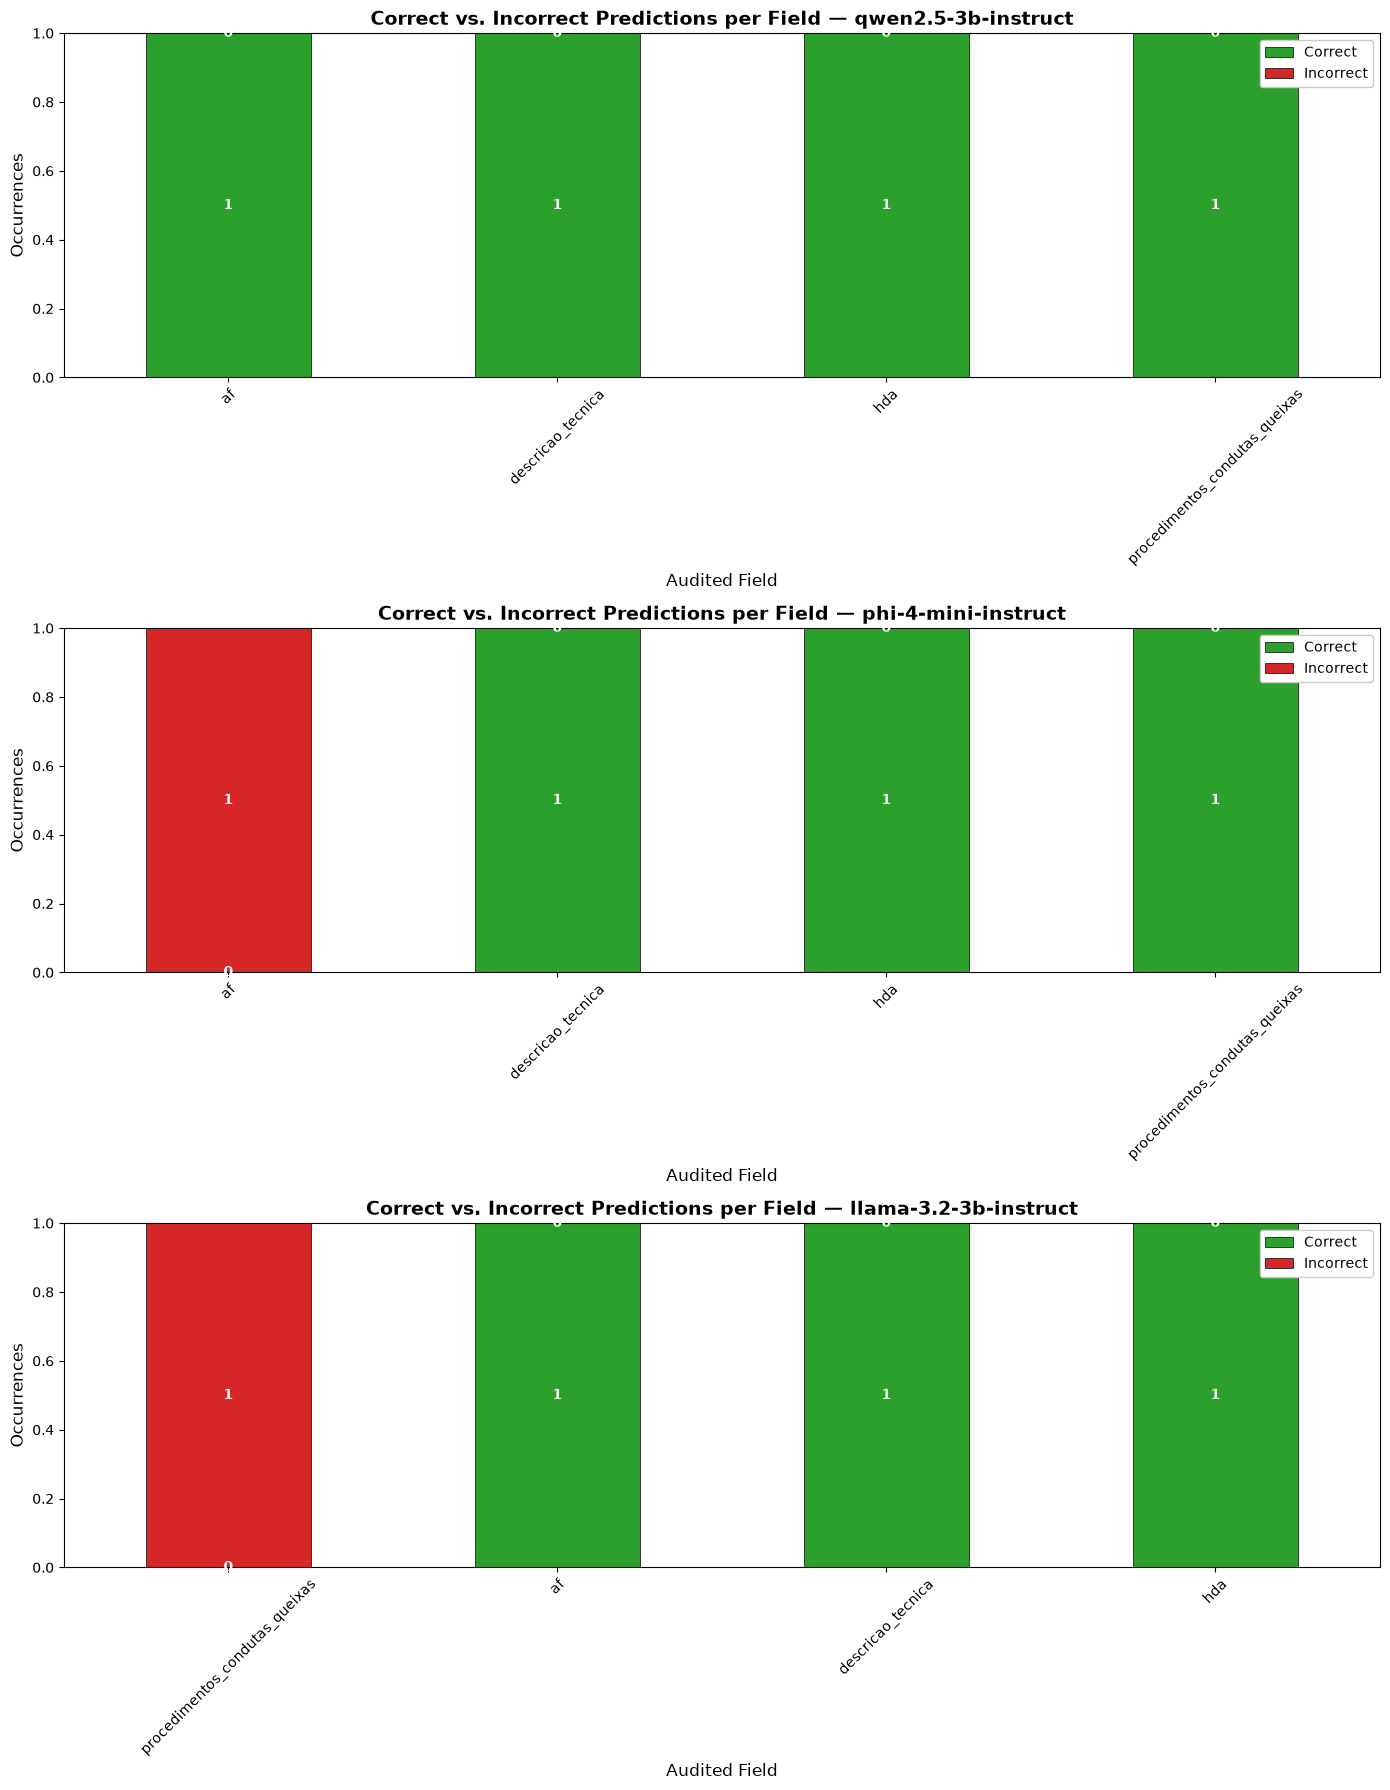

In [82]:
# Accuracy vs. Error per Field — integrated into the notebook flow
# Uses df_metrics, ALL_MODELS and ground_truth already defined in previous cells

# Normalize renamed fields (condutas == procedimentos_condutas_queixas)
df_plot = df_metrics.copy()
df_plot['field'] = df_plot['field'].replace({'condutas': 'procedimentos_condutas_queixas'})

# Keep only fields that exist in the ground truth
valid_fields = ground_truth['field'].unique().tolist()
df_plot = df_plot[df_plot['field'].isin(valid_fields)]

# Boolean hit column: does the prediction match the expected label?
df_plot['correct'] = df_plot['expected'] == df_plot['normalized_classification']

df_hits = df_plot.groupby(['model', 'field'])['correct'].value_counts().unstack(fill_value=0).reset_index()

if True not in df_hits.columns: df_hits[True] = 0
if False not in df_hits.columns: df_hits[False] = 0
df_hits.rename(columns={True: 'Correct', False: 'Incorrect'}, inplace=True)

fig, axes = plt.subplots(len(ALL_MODELS), 1, figsize=(14, 6 * len(ALL_MODELS)))
if len(ALL_MODELS) == 1: axes = [axes]

for i, model in enumerate(ALL_MODELS):
    subset = df_hits[df_hits['model'] == model].set_index('field')
    subset = subset.sort_values(by=['Incorrect', 'Correct'], ascending=[False, False])

    subset[['Correct', 'Incorrect']].plot(
        kind='bar', stacked=True, color=['#2ca02c', '#d62728'],
        ax=axes[i], edgecolor='black', linewidth=0.5
    )

    axes[i].set_title(f"Correct vs. Incorrect Predictions per Field — {model}", fontsize=14, fontweight='bold')
    axes[i].set_ylabel("Occurrences", fontsize=12)
    axes[i].set_xlabel("Audited Field", fontsize=12)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(loc='upper right', framealpha=1)

    for container in axes[i].containers:
        axes[i].bar_label(container, label_type='center', color='white', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


### 8.2 Confusion matrices per model

Two views of the same predictions. The **binary** one (conforme × não conforme) is what the auditor sees. The
**three-class** one (conforme × incompleto × ausente) is only for validating the model: a non-conformity can come
from a field that is *incomplete* (the AI found it and judged it so) or *absent* (the AI did not find it), and
the second matrix shows whether the model got the *kind* of failure right, not just that there was one. The
tables below count, per kind of expected failure, how many were flagged at all and how many with the right kind.

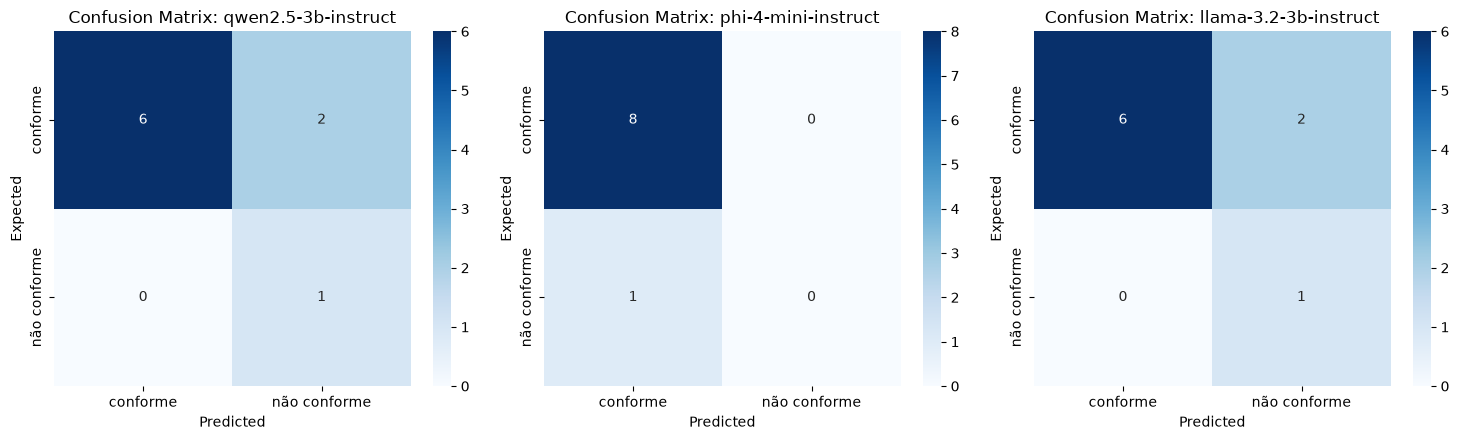

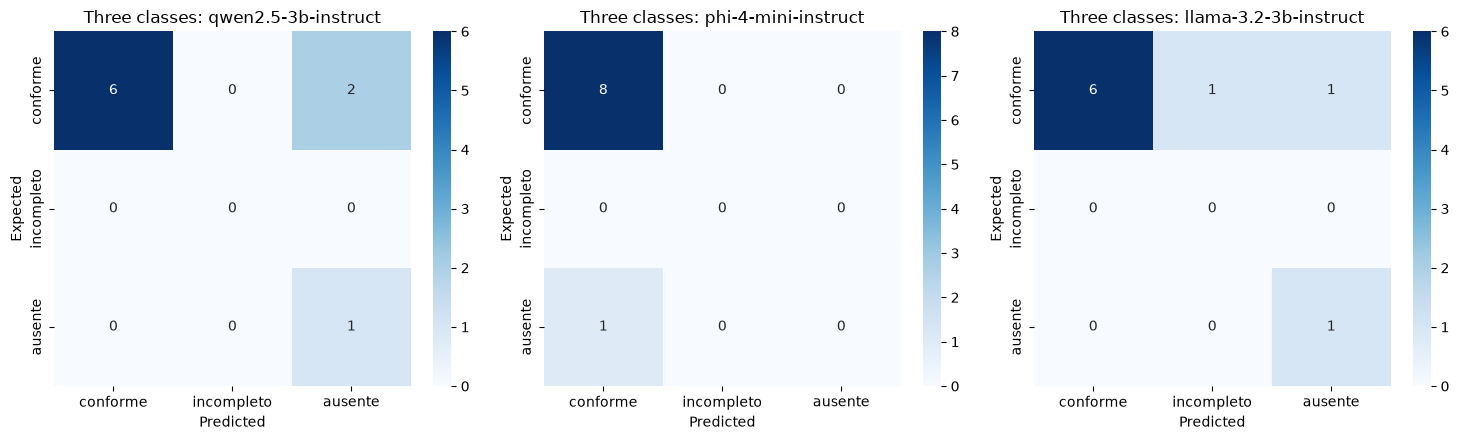

,model,expected_class,total,flagged,right_kind,flagged_rate,right_kind_rate
0,llama-3.2-3b-instruct,ausente,1,1,1,1.0,1.0
1,phi-4-mini-instruct,ausente,1,0,0,0.0,0.0
2,qwen2.5-3b-instruct,ausente,1,1,1,1.0,1.0


Rows per expected class and model:


expected_class,conforme,incompleto,ausente
model,,,
llama-3.2-3b-instruct,8,0,1
phi-4-mini-instruct,8,0,1
qwen2.5-3b-instruct,8,0,1


In [83]:
# The backend only knows "conforme" and "não conforme". The ground truth still separates
# 'ausente' and 'incompleta', but both mean "não conforme" here — the distinction is kept only to
# measure how well each model catches each kind of failure (table below the matrices).
labels_bin = ['conforme', 'não conforme']
to_label = {'present': 'conforme', 'absent': 'não conforme'}

df_metrics['expected_binary'] = df_metrics['expected'].map(to_label)
df_metrics['predicted_binary'] = df_metrics['normalized_classification'].map(to_label)

fig, axes = plt.subplots(1, len(ALL_MODELS), figsize=(5 * len(ALL_MODELS), 4.5))
if len(ALL_MODELS) == 1:
    axes = [axes]

for i, model in enumerate(ALL_MODELS):
    subset = df_metrics[df_metrics['model'] == model]
    if len(subset) == 0:
        continue

    cm = confusion_matrix(subset['expected_binary'], subset['predicted_binary'], labels=labels_bin)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=labels_bin, yticklabels=labels_bin)
    axes[i].set_title(f"Confusion Matrix: {model}")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Expected")

plt.tight_layout()
plt.show()

# --- Three-class matrices -------------------------------------------------------------------
labels_cls = ['conforme', 'incompleto', 'ausente']

fig, axes = plt.subplots(1, len(ALL_MODELS), figsize=(5 * len(ALL_MODELS), 4.5))
if len(ALL_MODELS) == 1:
    axes = [axes]

for i, model in enumerate(ALL_MODELS):
    subset = df_metrics[df_metrics['model'] == model]
    if len(subset) == 0:
        continue

    cm = confusion_matrix(subset['expected_class'], subset['predicted_class'], labels=labels_cls)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=labels_cls, yticklabels=labels_cls)
    axes[i].set_title(f"Three classes: {model}")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Expected")

plt.tight_layout()
plt.show()

# --- Detection of each kind of expected failure ----------------------------------------------
# flagged = the model said "não conforme" in any way; right_kind = it also said WHICH kind.
failures = df_metrics[df_metrics['expected_class'] != 'conforme'].copy()
failures['flagged'] = failures['predicted_class'] != 'conforme'
failures['right_kind'] = failures['predicted_class'] == failures['expected_class']
detection = (failures.groupby(['model', 'expected_class'])
             .agg(total=('flagged', 'count'), flagged=('flagged', 'sum'), right_kind=('right_kind', 'sum'))
             .reset_index())
detection['flagged_rate'] = (detection['flagged'] / detection['total']).round(3)
detection['right_kind_rate'] = (detection['right_kind'] / detection['total']).round(3)
display(detection)

# The counts per class in the sample, so a rate over 1 or 2 rows is not read as more than it is.
print("Rows per expected class and model:")
display(pd.crosstab(df_metrics['model'], df_metrics['expected_class']).reindex(columns=labels_cls, fill_value=0))


## 9. Latency metrics (critical for running on CPU / a notebook without a GPU)

In [84]:
# Time is measured per endpoint call (all fields for that record), not per individual field
df_times = df_raw.drop_duplicates(subset=['model', 'repetition', 'record'])[
    ['model', 'record', 'time_seconds']
]

latency_summary = df_times.groupby('model')['time_seconds'].agg(
    mean='mean', std='std', min='min', max='max'
).reset_index()

latency_summary.to_csv(RESULTS_DIR / 'latency_metrics.csv', index=False)
latency_summary


,model,mean,std,min,max
0,llama-3.2-3b-instruct,235.165995,NaN,235.165995,235.165995
1,phi-4-mini-instruct,160.126248,NaN,160.126248,160.126248
2,qwen2.5-3b-instruct,105.087451,NaN,105.087451,105.087451


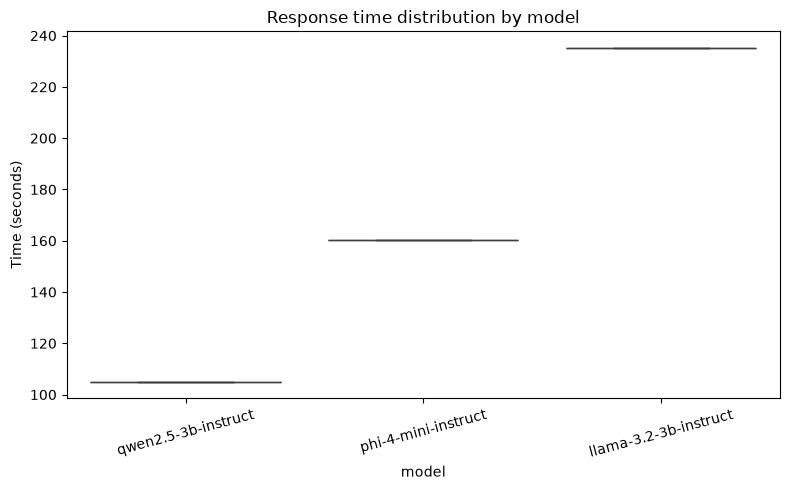

In [85]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_times, x='model', y='time_seconds')
plt.title('Response time distribution by model')
plt.ylabel('Time (seconds)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'latency_boxplot.png', dpi=150)
plt.show()


## 10. Technical error rate per model

Separates execution failures (timeout, invalid JSON, endpoint down) from content errors — important so a model isn't penalized for infrastructure instability.
`retry_rate_pct` is the share of AI attempts that had to be repeated (the backend tries each call up to 3 times); `error_rate_pct` is the share of fields the AI never processed (always 0 in a valid evaluation).

In [86]:
# Technical reliability of the AI calls, from the `_ia_meta` signature of every job.
# In strict mode a permanent failure aborts the run, so the error rate here reflects what
# made it through: fields without an answer (must be 0) and how many retries were needed.
df_meta_all = pd.read_csv(RESULTS_DIR / 'ia_meta.csv')

error_rate_df = df_meta_all.groupby('model').agg(
    total_calls=('ia_calls', 'sum'),
    total_attempts=('ia_attempts', 'sum'),
    fields_sent=('fields_sent', 'sum'),
    fields_error=('fields_error', 'sum'),
).reset_index()

error_rate_df['retries'] = error_rate_df['total_attempts'] - error_rate_df['total_calls']
error_rate_df['retry_rate_pct'] = (error_rate_df['retries'] / error_rate_df['total_attempts'] * 100).round(2)
error_rate_df['error_rate_pct'] = (error_rate_df['fields_error'] / error_rate_df['fields_sent'] * 100).round(2)
error_rate_df

,model,total_calls,total_attempts,fields_sent,fields_error,retries,retry_rate_pct,error_rate_pct
0,llama-3.2-3b-instruct,7,7,13,0,0,0.0,0.0
1,phi-4-mini-instruct,7,7,13,0,0,0.0,0.0
2,qwen2.5-3b-instruct,7,7,13,0,0,0.0,0.0


## 11. Final consolidated table — summary for the thesis

In [87]:
final_summary = df_quality_summary.merge(latency_summary, on='model').merge(
    error_rate_df[['model', 'error_rate_pct']], on='model'
)
final_summary = final_summary.round(3)
final_summary.to_csv(RESULTS_DIR / 'final_summary.csv', index=False)
final_summary


,model,n_samples,precision (Qualidade),recall (Qualidade),f1 (Qualidade),precision (Presença),recall (Presença),f1 (Presença),mean,std,min,max,error_rate_pct
0,qwen2.5-3b-instruct,9,1.000,0.75,0.857,1.000,0.75,0.857,105.087,NaN,105.087,105.087,0.0
1,phi-4-mini-instruct,9,0.889,1.00,0.941,0.889,1.00,0.941,160.126,NaN,160.126,160.126,0.0
2,llama-3.2-3b-instruct,9,1.000,0.75,0.857,1.000,0.75,0.857,235.166,NaN,235.166,235.166,0.0


---
## Manual next steps

1. Review `quality_metrics_by_field.csv` to identify which fields perform worst per model
2. Manually validate a sample of the error cases (`normalized_classification != expected`) to confirm whether they are real model failures or issues in the synthetic ground truth
3. Use `final_summary.csv` and the generated charts as the basis for the thesis tables/figures
4. To formally measure consistency/determinism, increase `N_REPETITIONS` to 3-5 and compute the agreement rate between repetitions